In [ ]:
from pgmpy.models import BayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination

# Define state names
state_names = {
    'Past Purchase History': ['Yes', 'No'],
    'Product Review Ratings': ['Good', 'Average', 'Bad'],
    'Discounts Available': ['Yes', 'No'],
    'Purchase Decision': ['Buy', 'Not Buy']
}

# Define Bayesian Network
model = BayesianNetwork([
    ('Past Purchase History', 'Purchase Decision'),
    ('Product Review Ratings', 'Purchase Decision'),
    ('Discounts Available', 'Purchase Decision')
])
# CPD for Past Purchase History
cpd_past_purchase = TabularCPD(
    variable='Past Purchase History', variable_card=2,
    values=[[0.7], [0.3]],
    state_names={'Past Purchase History': state_names['Past Purchase History']}
)

# CPD for Product Review Ratings
cpd_reviews = TabularCPD(
    variable='Product Review Ratings', variable_card=3,
    values=[[0.5], [0.3], [0.2]],
    state_names={'Product Review Ratings': state_names['Product Review Ratings']}
)

# CPD for Discounts Available
cpd_discounts = TabularCPD(
    variable='Discounts Available', variable_card=2,
    values=[[0.6], [0.4]],
    state_names={'Discounts Available': state_names['Discounts Available']}
)

# CPD for Purchase Decision
cpd_purchase = TabularCPD(
    variable='Purchase Decision', variable_card=2,
    values=[
        [0.9, 0.8, 0.6, 0.5, 0.3, 0.2, 0.7, 0.6, 0.4, 0.3, 0.1, 0.05],  # Buy
        [0.1, 0.2, 0.4, 0.5, 0.7, 0.8, 0.3, 0.4, 0.6, 0.7, 0.9, 0.95]   # Not Buy
    ],
    evidence=['Past Purchase History', 'Product Review Ratings', 'Discounts Available'],
    evidence_card=[2, 3, 2],
    state_names={
        'Past Purchase History': state_names['Past Purchase History'],
        'Product Review Ratings': state_names['Product Review Ratings'],
        'Discounts Available': state_names['Discounts Available'],
        'Purchase Decision': state_names['Purchase Decision']
    }
)

# Add CPDs to the model
model.add_cpds(cpd_past_purchase, cpd_reviews, cpd_discounts, cpd_purchase)

# Validate the model
print("Model validation:", model.check_model())



Model validation: True


In [ ]:
from pgmpy.inference import VariableElimination


result = inference.query(variables=['Purchase Decision'],
                         evidence={'Past Purchase History': 'Yes', 'Product Review Ratings': 'Good', 'Discounts Available': 'No'})
print(result)

+----------------------------+--------------------------+
| Purchase Decision          |   phi(Purchase Decision) |
+============================+==========================+
| Purchase Decision(Buy)     |                   0.8000 |
+----------------------------+--------------------------+
| Purchase Decision(Not Buy) |                   0.2000 |
+----------------------------+--------------------------+


In [ ]:
# Perform inference
inference = VariableElimination(model)
result = inference.query(
    variables=['Purchase Decision'],
    evidence={'Product Review Ratings': 'Good','Discounts Available': 'Yes'})
print(result)

+----------------------------+--------------------------+
| Purchase Decision          |   phi(Purchase Decision) |
+============================+==========================+
| Purchase Decision(Buy)     |                   0.8400 |
+----------------------------+--------------------------+
| Purchase Decision(Not Buy) |                   0.1600 |
+----------------------------+--------------------------+


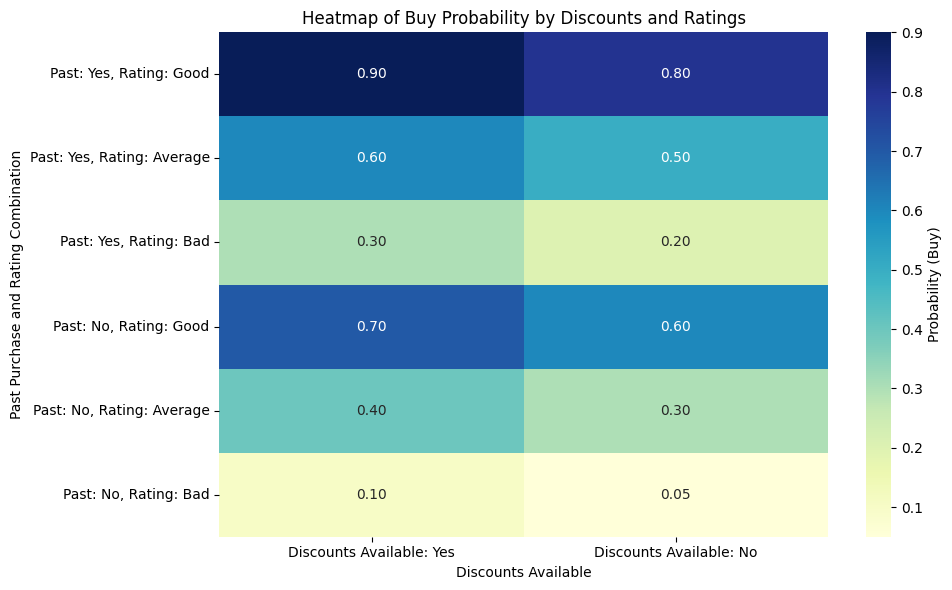

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Define the table as a DataFrame
data = {
    'Discounts Available: Yes': [0.9, 0.6, 0.3, 0.7, 0.4, 0.1],
    'Discounts Available: No': [0.8, 0.5, 0.2, 0.6, 0.3, 0.05]
}
index = [
    'Past: Yes, Rating: Good',
    'Past: Yes, Rating: Average',
    'Past: Yes, Rating: Bad',
    'Past: No, Rating: Good',
    'Past: No, Rating: Average',
    'Past: No, Rating: Bad'
]
df = pd.DataFrame(data, index=index)

# Create the heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(df, annot=True, cmap="YlGnBu", fmt=".2f", cbar_kws={'label': 'Probability (Buy)'})
plt.title('Heatmap of Buy Probability by Discounts and Ratings')
plt.ylabel('Past Purchase and Rating Combination')
plt.xlabel('Discounts Available')
plt.tight_layout()

# Show the heatmap
plt.show()